# 03 · Differential expression (DESeq2)
- **Goal:** what changes in each comparison, on its own: aging (older vs 3 months, and the course over age) and each treatment vs its control. How the treatments relate to aging is notebook 05.
- **Input:** RSEM gene counts (`METHOD`; notebook 04 checks kallisto). **Output:** `results/de/<METHOD>/`: DE table per comparison (not in git) and `deg_annotation.csv` (all DEGs with gene names, in git).
- **Kernel:** R (`ir`) · **Time:** ~1 min.

**Method**
- DESeq2 fits a negative binomial model per gene and tests whether the log2 fold change differs from 0.
- **padj** = p-value adjusted for testing ~17,000 genes at once (Benjamini–Hochberg): among genes with padj < 0.05, about 5 % are expected to be false positives.
- DEG (differentially expressed gene) = padj < 0.05.
- A gene is tested only if it has ≥ 10 counts in at least as many samples as the smallest group.
- Gene names and types: org.Mm.eg.db (NCBI Gene).

**Design:** aging and rejuvenation mice come from different experiments, so they are analysed **separately**, each treatment against its own control.

| Analysis | Mice | Model | Comparison |
|---|---|---|---|
| Aging | 12 (3 / 18 / 21 months, 2 male + 2 female each) | `~ sex + group` | 18 vs 3, 21 vs 3 months |
| aDR | 9 females (AL 4, aDR 5) | `~ group` | aDR vs AL |
| YMP | 6 males (PBS 3, YMP 3) | `~ group` | YMP vs PBS |

Terms: [docs/glossary.md](../docs/glossary.md).

In [1]:
# samples: one row per run; genes: gene id -> symbol; txi: gene-level counts of METHOD
source('../R/helpers.R')
samples <- load_samples()
genes <- load_genes()
METHOD <- 'RSEM'   # or 'kallisto' to repeat the analysis with kallisto
txi <- switch(METHOD, RSEM = load_rsem(rownames(samples)), kallisto = load_txi(rownames(samples))$txi)

## 1 · All 27 samples: the cohort effect
Two views of sample similarity (variance-stabilised counts):
- a PCA;
- a hierarchical clustering on pairwise correlations.

Both should separate the two cohorts, which is why they are not pooled.

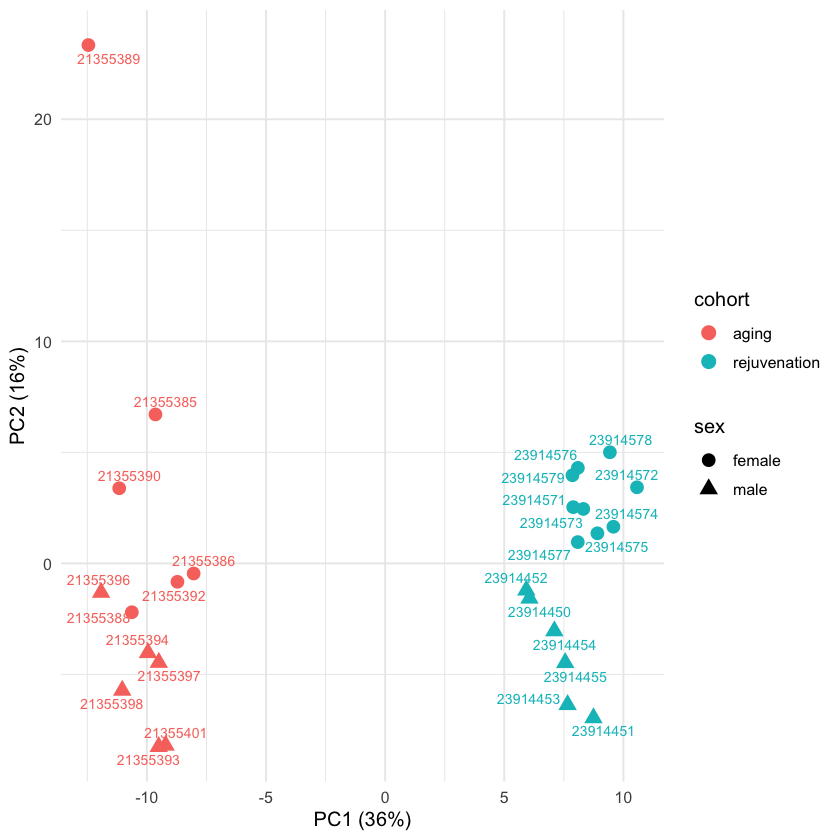

In [2]:
# DESeq2 dataset of all 27 samples; design ~ 1 = no groups (only for the plot, nothing is tested here);
# genes with >= 10 counts in >= 4 samples are kept
dds_all <- make_dds(txi, samples, ~ 1, min_n = 4)
# PCA of the variance-stabilised counts (vst, blind to the groups); colour = cohort, shape = sex, label = run number
pca_plot(dds_all, 'cohort', 'sex')

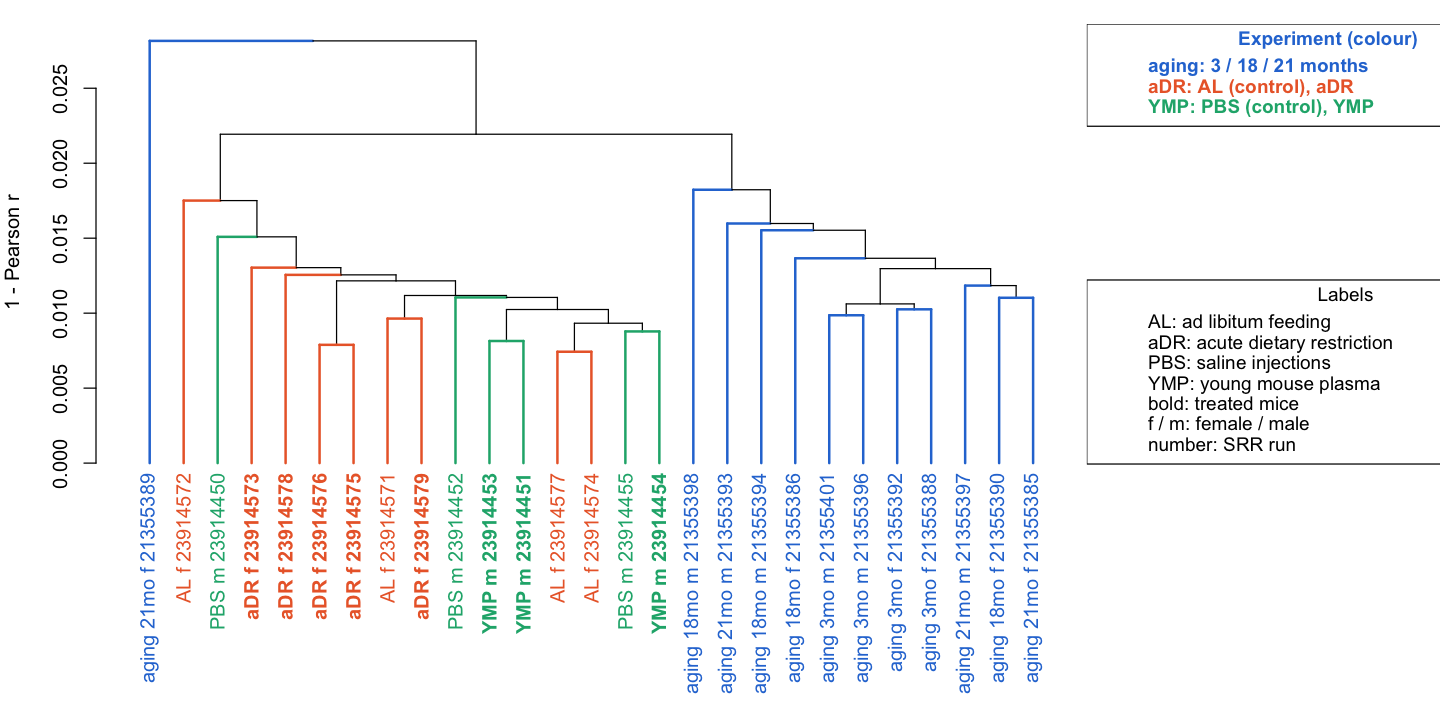

In [3]:
# hierarchical clustering of the samples: distance = 1 - Pearson correlation of the vst values (same genes as the PCA)
options(repr.plot.width = 12, repr.plot.height = 6)
sample_tree(dds_all)

**Reading**
- The outlier SRR21355389 branches off first; then the two cohorts split completely.
- Aging cohort: the four 3-month mice form one branch; 18 and 21 months are mixed.
- Rejuvenation cohort: the groups do not form their own branches, so the treatment effects are small compared with the differences between mice.
- All samples are very similar (1 − r < 0.03 at every merge), as expected for one tissue.

## 2 · Aging cohort (3, 18, 21 months)
### 2a · Outlier check
- With all 12 mice, one 21-month female (SRR21355389) sits far from the others on PC1.

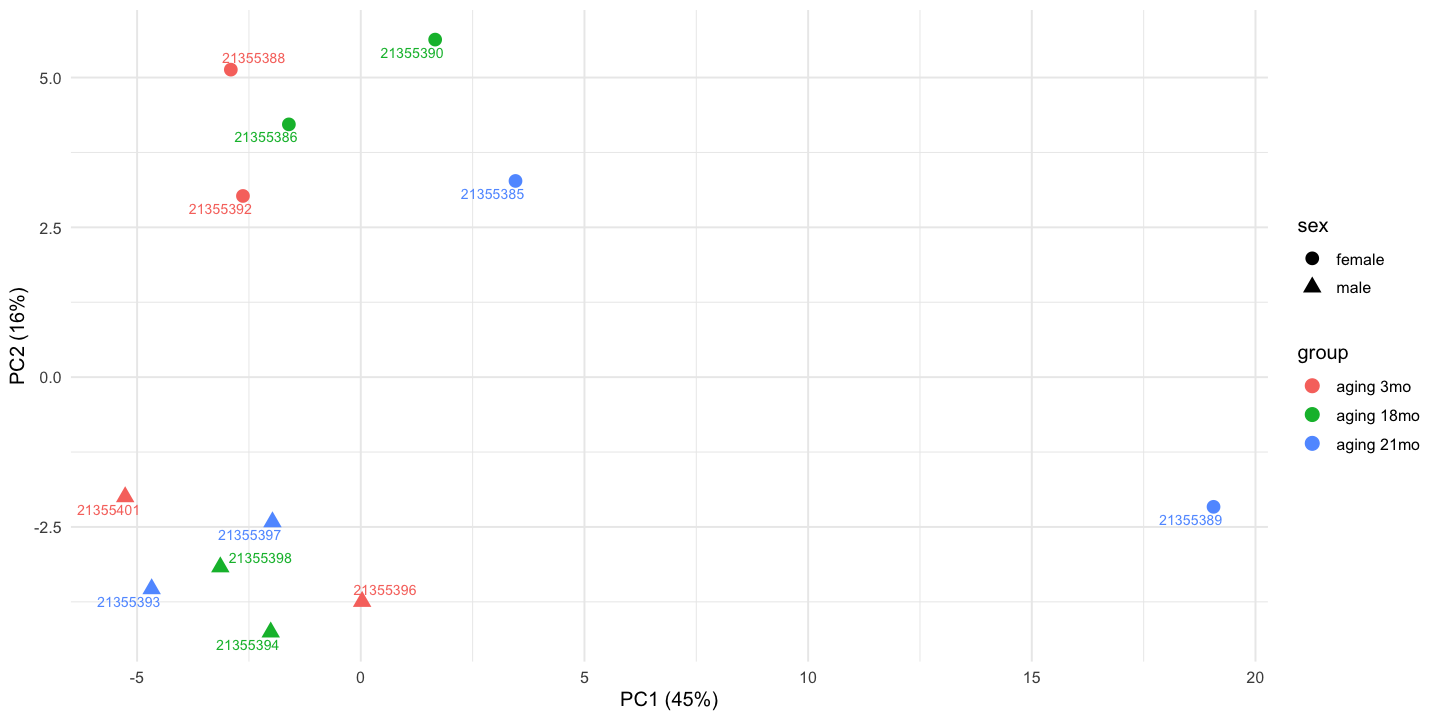

In [4]:
# aging mice only, all 12; PCA coloured by age group
s_age_all <- samples %>% filter(cohort == 'aging') %>% mutate(group = droplevels(group))
dds_age_all <- make_dds(txi, s_age_all, ~ sex + group, min_n = 4)
pca_plot(dds_age_all, 'group', 'sex')

In [5]:
# the 10 genes that most distinguish SRR21355389 from the other 11 aging mice: its vst value minus their mean (≈ log2 difference)
outlier_genes(dds_age_all, 'SRR21355389', genes)

symbol,vst_diff
<chr>,<dbl>
Hbb-bs,5.074086
Hba-a1,5.045218
S100a8,4.830856
Hba-a2,4.697898
Hbb-bt,4.472360
Ngp,4.371122
S100a9,4.327058
Col1a1,3.795261
Col1a2,3.192967


**Its top genes** are all higher than in the other mice (`vst_diff` ≈ log2 difference, so 5 ≈ 32×):
- **haemoglobins** (Hbb-bs, Hba-a1/a2, Hbb-bt): red blood cells;
- **neutrophil and myeloid** genes (S100a8/9, Ngp, Lyz2);
- **collagens** (Col1a1/2): meninges, vessels.

This suggests blood and meningeal tissue in the sample (e.g. incomplete perfusion), so we treat it as potentially contaminated (inferred from expression only).

**Decision:** exclude it from the aging analysis (`EXCLUDE`; `character(0)` keeps it). Keeping it would double the 21 vs 3 month DEGs (239 vs 114 on genes tested in both), but 106 of the 114 stay significant in the same direction, so the aging signal does not depend on this choice (notebook 04, section 4).

In [6]:
# the 11 aging mice used from here on, and their DESeq2 model (sex as covariate; genes with >= 10 counts in >= 3 samples,
# the size of the smallest group)
EXCLUDE <- 'SRR21355389'
s_age <- s_age_all[!rownames(s_age_all) %in% EXCLUDE, ]
dds_age <- make_dds(txi, s_age, ~ sex + group, min_n = 3)

### 2b · Aging DEGs
- Outlier excluded (the analysis used from here on).
- Up = higher in the older group.
- Together, 173 genes are DEGs in at least one of the two comparisons.

In [7]:
# DE tables for 18 vs 3 and 21 vs 3 months; counts of up / down DEGs
age <- list(`18v3` = de_table(dds_age, c('group', 'aging 18mo', 'aging 3mo'), genes),
            `21v3` = de_table(dds_age, c('group', 'aging 21mo', 'aging 3mo'), genes))
bind_rows(lapply(age, n_deg), .id = 'contrast')

contrast,up,down
<chr>,<int>,<int>
18v3,95,20
21v3,74,42


In [8]:
# the 10 most significant DEGs per comparison, with gene name (org.Mm.eg.db)
annotate_degs(age) %>% group_by(comparison) %>% slice_min(padj, n = 10, with_ties = FALSE) %>% select(comparison, symbol, name, log2FC, padj)

comparison,symbol,name,log2FC,padj
<chr>,<chr>,<chr>,<dbl>,<dbl>
18v3,C4b,complement C4B (Chido blood group),2.31,2.5e-23
18v3,Gfap,glial fibrillary acidic protein,1.11,4.3e-23
18v3,Fam163b,"family with sequence similarity 163, member B",1.67,1.7e-22
18v3,Ctss,cathepsin S,1.20,9.4e-14
18v3,C1qb,"complement component 1, q subcomponent, beta polypeptide",1.21,1.4e-13
18v3,Ctsd,cathepsin D,0.63,3.1e-11
18v3,Clec7a,"C-type lectin domain family 7, member a",3.55,2.3e-10
18v3,Tyrobp,TYRO protein tyrosine kinase binding protein,1.48,1.4e-09
18v3,C1qc,"complement component 1, q subcomponent, C chain",1.13,2.3e-08


### 2c · Patterns of the aging DEGs over age
The 173 aging DEGs (2b), grouped by their course from 3 to 18 to 21 months:
1. **Profile** per gene: log2FC vs 3 months at 3, 18 and 21 months, i.e. (0, 18 vs 3, 21 vs 3), from the DESeq2 model (adjusted for sex).
2. **Distance:** 1 − Pearson correlation of two profiles, so genes are grouped by **shape, not size** (0 → 2 → 2 and 0 → 0.5 → 0.5 are identical).
3. **Hierarchical clustering** (average linkage), with the tree **cut into 4 clusters**; 4 is our choice.

In [9]:
# one row per aging DEG: cluster and log2FC at 18 and 21 months; per cluster: size, median log2FC, the 5 genes with the largest change at 21 months
pat <- deg_patterns(age, k = 4)
pat %>% group_by(cluster) %>% summarise(genes = n(), median_lfc_18v3 = round(median(lfc_18v3), 2), median_lfc_21v3 = round(median(lfc_21v3), 2),
  examples = paste(head(symbol[order(-abs(lfc_21v3))], 5), collapse = ', '))

cluster,genes,median_lfc_18v3,median_lfc_21v3,examples
<int>,<int>,<dbl>,<dbl>,<chr>
1,111,1.11,1.02,"Cst7, Ccl3, Ostn, Lilrb4a, Clec7a"
2,45,-0.24,-0.69,"Tlx3, Agtr2, Mkrn3, Sh3gl3, Gpr17"
3,10,-0.41,-0.20,"Thbs3, Dapk1, Hspa5, Gm32113, Scn2b"
4,7,0.64,0.10,"Hspg2, Gm66006, Rin2, Wdr6, Neat1"


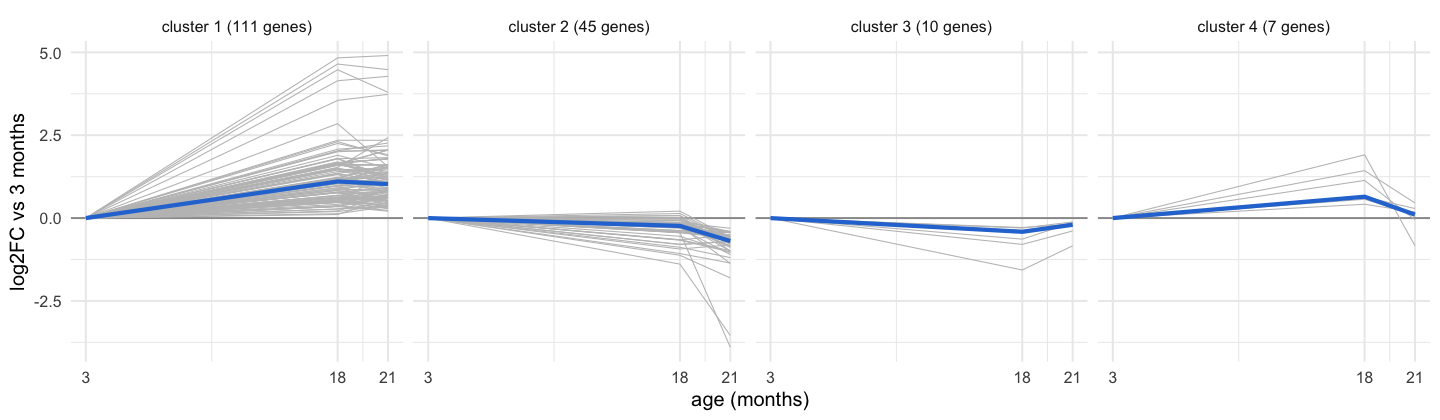

In [10]:
options(repr.plot.width = 12, repr.plot.height = 3.5)
deg_pattern_plot(pat)

**Reading**
- Cluster 1 (111 genes): rise by 18 months and stay up, e.g. microglia / inflammation genes Cst7, Ccl3, Clec7a, C4b.
- Cluster 2 (45 genes): fall, mainly between 18 and 21 months.
- Clusters 3 and 4 (10 and 7 genes): change at 18 months and partly return at 21; with 3–4 mice per group this may be noise.
- 4 clusters is a choice; with three time points few distinct shapes exist.

## 3 · Rejuvenation: aDR vs AL (females) and YMP vs PBS (males)
- One model per treatment, each against its own control.
- DEG counts are not comparable between the two: aDR has 9 mice, YMP 6, so less power to call DEGs.

In [11]:
# one DESeq2 model per treatment (each against its own control); counts of up / down DEGs
s_adr <- samples %>% filter(group %in% c('AL', 'aDR')) %>% mutate(group = droplevels(group))
s_ymp <- samples %>% filter(group %in% c('PBS', 'YMP')) %>% mutate(group = droplevels(group))
dds_adr <- make_dds(txi, s_adr, ~ group, min_n = 4)
dds_ymp <- make_dds(txi, s_ymp, ~ group, min_n = 3)
rej <- list(aDR = de_table(dds_adr, c('group', 'aDR', 'AL'), genes),
            YMP = de_table(dds_ymp, c('group', 'YMP', 'PBS'), genes))
bind_rows(lapply(rej, n_deg), .id = 'contrast')

contrast,up,down
<chr>,<int>,<int>
aDR,46,72
YMP,22,28


In [12]:
# the 10 most significant DEGs per treatment, with gene name
annotate_degs(rej) %>% group_by(comparison) %>% slice_min(padj, n = 10, with_ties = FALSE) %>% select(comparison, symbol, name, log2FC, padj)

comparison,symbol,name,log2FC,padj
<chr>,<chr>,<chr>,<dbl>,<dbl>
YMP,Ptgds,prostaglandin D2 synthase (brain),-1.46,3.0e-24
YMP,Zftraf1,zinc finger TRAF type containing 1,1.50,3.1e-06
YMP,Nefl,"neurofilament, light polypeptide",0.74,1.3e-05
YMP,Ogn,osteoglycin,-2.13,1.8e-05
YMP,Ccn3,cellular communication network factor 3,-4.23,5.8e-05
YMP,Nefm,"neurofilament, medium polypeptide",0.72,6.5e-05
YMP,A730009L09Rik,RIKEN cDNA A730009L09 gene,-2.70,1.0e-04
YMP,Gm12895,NA,7.05,2.3e-04
YMP,Ttn,titin,2.33,3.6e-04


## 4 · Save
- One CSV per comparison with all tested genes (DESeq2 columns and gene symbol).
- `deg_annotation.csv`: every DEG with name, type, log2FC, padj and, for aging DEGs, its cluster (2c).

In [13]:
# writes results/de/<METHOD>/<comparison>.csv and deg_annotation.csv
dir.create(file.path(ROOT, 'results/de', METHOD), recursive = TRUE, showWarnings = FALSE)
res <- c(setNames(age, paste0('aging_', names(age))), rej)
invisible(imap(res, \(r, n) write_csv(r, file.path(ROOT, 'results/de', METHOD, paste0(n, '.csv')))))
ann <- annotate_degs(res) %>% left_join(select(pat, gene_id, aging_cluster = cluster), by = 'gene_id') %>%
  mutate(aging_cluster = if_else(startsWith(comparison, 'aging'), aging_cluster, NA_integer_)) %>% relocate(gene_id, .after = last_col())
write_csv(ann, file.path(ROOT, 'results/de', METHOD, 'deg_annotation.csv'))
list.files(file.path(ROOT, 'results/de', METHOD))

[1] "aDR.csv"            "aging_18v3.csv"     "aging_21v3.csv"    
[4] "deg_annotation.csv" "YMP.csv"